# Operator Learning on the poisson model
1. The poisson model and numerical solver
2. Generating samples for the initial condition (via GP)
3. Train a FNO

## 1. The poisson model and numerical solver

L∞ error: 8.233e-05


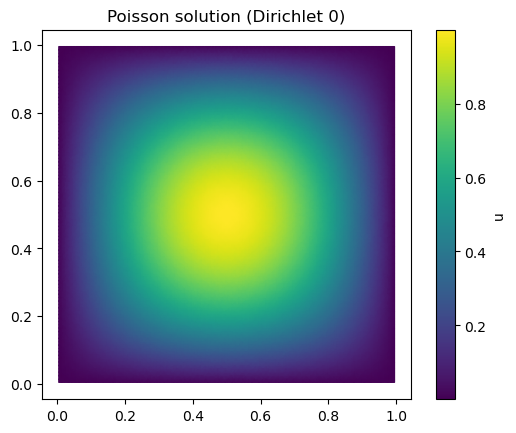

In [5]:
from fipy import Grid2D, CellVariable, DiffusionTerm, numerix as np
import numpy as onp
import matplotlib.pyplot as plt


N = 100
L = 1.0
dx = L / N
mesh = Grid2D(nx=N, ny=N, dx=dx, dy=dx)

u = CellVariable(name="u", mesh=mesh, value=0.0)
u.constrain(0.0, where=mesh.exteriorFaces)

xc, yc = mesh.cellCenters
f = 2 * np.pi**2 * np.sin(np.pi*xc) * np.sin(np.pi*yc)
f_cv = CellVariable(mesh=mesh, value=f)

eq = DiffusionTerm(var=u) == -f_cv
eq.solve(var=u)

u_exact = np.sin(np.pi*xc) * np.sin(np.pi*yc)
err_Linf = onp.max(onp.abs(u.value - u_exact))
print(f"L∞ error: {err_Linf:.3e}")

plt.figure()
plt.tripcolor(xc, yc, u.value, shading="gouraud")
plt.colorbar(label="u")
plt.gca().set_aspect("equal", adjustable="box")
plt.title("Poisson solution (Dirichlet 0)")
plt.show()



In [6]:
print(f_cv.shape)

(10000,)


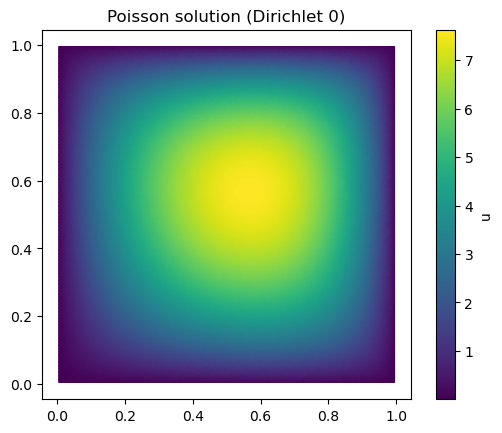

In [7]:
u = CellVariable(name="u", mesh=mesh, value=0.0)
u.constrain(0.0, where=mesh.exteriorFaces)

xc, yc = mesh.cellCenters
f = 100*xc + 100 * yc
f_cv = CellVariable(mesh=mesh, value=f)

eq = DiffusionTerm(var=u) == -f_cv
eq.solve(var=u)


plt.figure()
plt.tripcolor(xc, yc, u.value, shading="gouraud")
plt.colorbar(label="u")
plt.gca().set_aspect("equal", adjustable="box")
plt.title("Poisson solution (Dirichlet 0)")
plt.show()

## 2. Generate samples for initial condition of the problem
To generate samples, we take a Gaussian process and sample from it.

In [8]:
from __future__ import annotations
from dataclasses import dataclass
from functools import cached_property
from typing import Tuple

import jax
import jax.numpy as jnp
from jaxtyping import Float, Array

# --- stability: 64-bit helps Cholesky on larger grids ---
jax.config.update("jax_enable_x64", True)

@dataclass
class Gaussian:
    mu: Float[Array, "N"]
    Sigma: Float[Array, "N N"]
    jitter: float = 1e-6

    @cached_property
    def L(self) -> Float[Array, "N N"]:
        n = self.Sigma.shape[0]
        # enforce symmetry (tiny fp errors can hurt Cholesky)
        S = 0.5 * (self.Sigma + self.Sigma.T)
        return jnp.linalg.cholesky(S + self.jitter * jnp.eye(n, dtype=S.dtype))

    def sample(self, key: jax.random.KeyArray, num_samples: int = 1
               ) -> Float[Array, "num_samples N"]:
        n = self.mu.shape[0]
        z = jax.random.normal(key, shape=(num_samples, n), dtype=self.mu.dtype)
        return self.mu + z @ self.L.T


def rbf_kernel(
    X: Float[Array, "N 2"], Y: Float[Array, "M 2"],
    variance: float = 1.0, lengthscales: Tuple[float, float] = (0.2, 0.2),
    dtype=jnp.float64
) -> Float[Array, "N M"]:
    ℓx, ℓy = lengthscales
    Xs = X / jnp.array([ℓx, ℓy], dtype=dtype)
    Ys = Y / jnp.array([ℓx, ℓy], dtype=dtype)
    diff = Xs[:, None, :] - Ys[None, :, :]
    sqdist = jnp.sum(diff * diff, axis=-1)
    return jnp.asarray(variance, dtype=dtype) * jnp.exp(-0.5 * sqdist)


def sample_gp_on_grid(
    key: jax.random.KeyArray,
    nx: int = 80, ny: int = 80,
    xlim=(0.0, 1.0), ylim=(0.0, 1.0),
    variance: float = 1.0, lengthscales=(0.15, 0.25),
    jitter: float = 1e-5, num_samples: int = 1,
    dtype=jnp.float64
):
    xs = jnp.linspace(xlim[0], xlim[1], nx, dtype=dtype)
    ys = jnp.linspace(ylim[0], ylim[1], ny, dtype=dtype)
    Xg, Yg = jnp.meshgrid(xs, ys, indexing="xy")       # (ny, nx)
    XY = jnp.stack([Xg.ravel(), Yg.ravel()], axis=-1)  # (N,2), N=nx*ny

    K = rbf_kernel(XY, XY, variance=variance, lengthscales=lengthscales, dtype=dtype)
    mu = jnp.zeros(K.shape[0], dtype=dtype)
    gp = Gaussian(mu=mu, Sigma=K, jitter=jitter)

    key, sub = jax.random.split(key)
    samples_flat = gp.sample(sub, num_samples=num_samples)         # (S, N)
    samples_img = samples_flat.reshape(num_samples, ny, nx)        # (S, ny, nx)
    return samples_img, xs, ys


In [9]:
# Plot of a gp sample

import numpy as onp
import matplotlib.pyplot as plt

key = jax.random.PRNGKey(356)  # <-- correct key ctor

min: -5.116897584182346 max: 5.691821166396084 std: 2.0543847434261897 has_nan: False


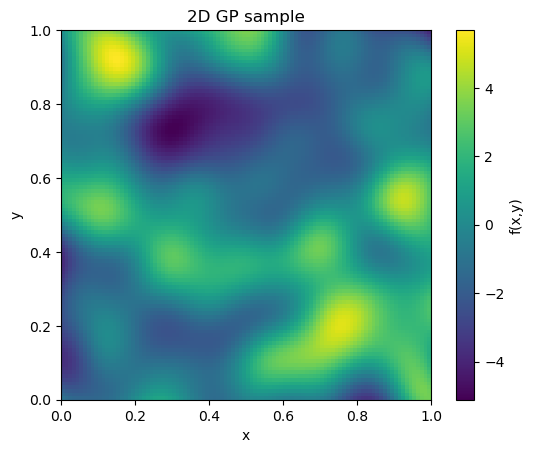

In [10]:
samples, xs, ys = sample_gp_on_grid(
    key, nx=N, ny=N,
    variance=5.0, lengthscales=(0.1, 0.1),
    jitter=1e-5, num_samples=1
)
s0 = onp.array(samples[2])  # to NumPy for plotting
print("min:", onp.nanmin(s0), "max:", onp.nanmax(s0), "std:", onp.nanstd(s0),
          "has_nan:", onp.isnan(s0).any())

# simplest, robust visualization:
plt.figure()
plt.imshow(s0, origin="lower", extent=[float(xs[0]), float(xs[-1]), float(ys[0]), float(ys[-1])], aspect="equal")
plt.colorbar(label="f(x,y)")
plt.title("2D GP sample")
plt.xlabel("x"); plt.ylabel("y")
plt.show()

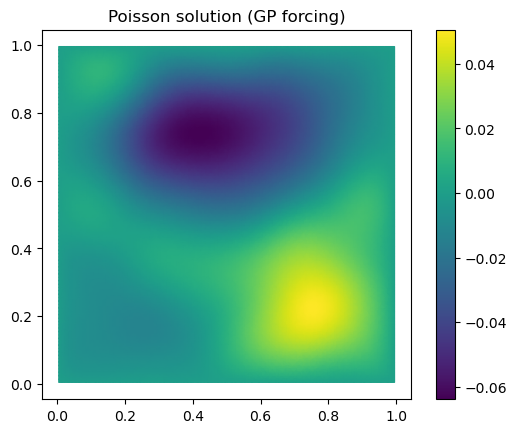

In [11]:
# s0 is shape (N, N). Flatten x-fastest to match FiPy cell order.
s_flat = onp.asarray(s0).ravel(order="C")              # length = N*N
assert s_flat.size == mesh.numberOfCells

f_cv = CellVariable(mesh=mesh, value=s_flat)

u = CellVariable(name="u", mesh=mesh, value=0.0)
u.constrain(0.0, where=mesh.exteriorFaces)
eq = DiffusionTerm(var=u) == -f_cv
eq.solve(var=u)

# Plot
plt.figure()
plt.tripcolor(*mesh.cellCenters, u.value, shading="gouraud")
plt.colorbar(); plt.gca().set_aspect("equal", adjustable="box")
plt.title("Poisson solution (GP forcing)")
plt.show()

### Generate Dataset
We generate the Training data by sampling the initial condition from a Gaussian process and then solve the pde numerically

In [12]:
num_samples = 1000
frac_train = 0.7
solution = np.zeros(shape=(num_samples,N,N))
samples, xs, ys = sample_gp_on_grid(
    key, nx=N, ny=N,
    variance=5.0, lengthscales=(0.1, 0.1),
    jitter=1e-5, num_samples=num_samples
)
for i in range(len(samples)):
    s = onp.array(samples[i])  # to NumPy for plotting
    # s0 is shape (N, N). Flatten x-fastest to match FiPy cell order.
    s_flat = onp.asarray(s).ravel(order="C")              # length = N*N
    assert s_flat.size == mesh.numberOfCells

    f_cv = CellVariable(mesh=mesh, value=s_flat)

    u = CellVariable(name="u", mesh=mesh, value=0.0)
    u.constrain(0.0, where=mesh.exteriorFaces)
    eq = DiffusionTerm(var=u) == -f_cv
    eq.solve(var=u)
    u_grid = u.value.reshape((N, N), order="C")  # shape back to grid
    solution[i] = u_grid
    

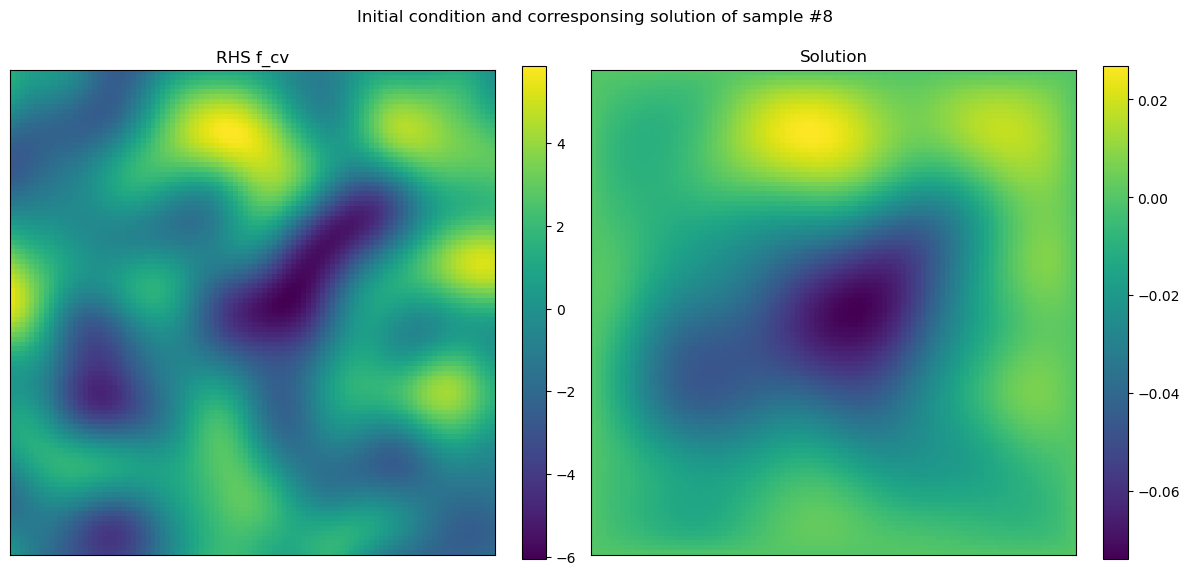

In [13]:
idx = 8
# --- plot ---
fig, axs = plt.subplots(1,2, figsize=(12,6))
im0 = axs[0].imshow(samples[idx], origin="lower", cmap="viridis")
axs[0].set_title("RHS f_cv")
plt.colorbar(im0, ax=axs[0], fraction=0.046)

im1 = axs[1].imshow(solution[idx], origin="lower", cmap="viridis")
axs[1].set_title("Solution")
plt.colorbar(im1, ax=axs[1], fraction=0.046)


for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle(f"Initial condition and corresponsing solution of sample #{idx}")
plt.tight_layout()

## 3. Train a FNO on the Dataset
The goal is to train an operator to approximate the solution map on the created dataset.

In [14]:
# fno2d_train.py
from __future__ import annotations
import math
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torch.nn import BatchNorm2d
torch.set_default_dtype(torch.float32)


In [15]:
# -----------------------------
# Dataset / Normalization
# -----------------------------
class GridPairDataset(Dataset):
    def __init__(self, X, Y, add_xy=True, normalize=True):
        assert X.shape == Y.shape and X.ndim == 3, "Expect (B, N, N)"
        self.X = torch.from_numpy(X)
        self.Y = torch.from_numpy(Y)
        self.add_xy = add_xy
        self.normalize = normalize

        # Stats for normalization (per-dataset scalar)
        if self.normalize:
            self.x_mean = self.X.mean()
            self.x_std  = self.X.std().clamp_min(1e-6)
            self.y_mean = self.Y.mean()
            self.y_std  = self.Y.std().clamp_min(1e-6)
        else:
            self.x_mean = self.x_std = self.y_mean = self.y_std = None

        # Pre-build positional grid (x,y) in [0,1]x[0,1]
        N = X.shape[1]
        xs = torch.linspace(0, 1, N)
        ys = torch.linspace(0, 1, N)
        Xg, Yg = torch.meshgrid(xs, ys, indexing="xy")
        self.xy = torch.stack([Xg, Yg], dim=0)  # (2, N, N)

    def __len__(self):
        return self.X.shape[0]
    
    def __shape__(self):
        return self.__shape__


    def __getitem__(self, idx):
        u0 = self.X[idx]  # (N,N)
        y  = self.Y[idx]  # (N,N)

        if self.normalize:
            u0 = (u0 - self.x_mean) / self.x_std
            y  = (y  - self.y_mean) / self.y_std

        u0 = u0.unsqueeze(0)  # (1,N,N)
        if self.add_xy:
            x_in = torch.cat([u0, self.xy], dim=0)  # (3,N,N): [u0, x, y]
        else:
            x_in = u0  # (1,N,N)

        return x_in, y.unsqueeze(0)  # input (C_in,N,N), target (1,N,N)
    
    
    def train_val_split(self, val_ratio=0.2, seed=None):
        """
        Split dataset into train/validation subsets.
        
        Args:
            val_ratio (float): Fraction of data to use for validation.
            seed (int, optional): Random seed for reproducibility.
        
        Returns:
            train_ds, val_ds (torch.utils.data.Dataset, torch.utils.data.Dataset)
        """
        n_total = len(self)
        n_val = int(n_total * val_ratio)
        n_train = n_total - n_val

        g = torch.Generator()
        if seed is not None:
            g.manual_seed(seed)

        train_ds, val_ds = random_split(self, [n_train, n_val], generator=g)
        return train_ds, val_ds




In [ ]:
# -----------------------------
# Dataset / Normalization (MPS-safe: float32 everywhere)
# -----------------------------
import numpy as np
import torch
from torch.utils.data import Dataset, random_split

class GridPairDataset(Dataset):
    def __init__(self, X, Y, add_xy=True, normalize=True):
        """
        X, Y: either np.ndarray or torch.Tensor with shape (B, N, N).
        They will be converted to float32 on CPU to be MPS-friendly.
        """
        # --- coerce to torch.float32 on CPU ---
        if isinstance(X, np.ndarray):
            X = torch.from_numpy(np.asarray(X, dtype=np.float32))
        elif isinstance(X, torch.Tensor):
            X = X.detach().cpu().to(torch.float32)
        else:
            raise TypeError("X must be np.ndarray or torch.Tensor")

        if isinstance(Y, np.ndarray):
            Y = torch.from_numpy(np.asarray(Y, dtype=np.float32))
        elif isinstance(Y, torch.Tensor):
            Y = Y.detach().cpu().to(torch.float32)
        else:
            raise TypeError("Y must be np.ndarray or torch.Tensor")

        assert X.shape == Y.shape and X.ndim == 3, "Expect (B, N, N)"
        self.X = X.contiguous()
        self.Y = Y.contiguous()

        self.add_xy = add_xy
        self.normalize = normalize

        # --- stats for normalization (scalars, float32) ---
        if self.normalize:
            # Use torch.float32 ops and clamp std to avoid division by ~0
            self.x_mean = self.X.mean()
            self.x_std  = self.X.std().clamp_min(1e-6)
            self.y_mean = self.Y.mean()
            self.y_std  = self.Y.std().clamp_min(1e-6)
        else:
            # keep as None to skip normalization in __getitem__
            self.x_mean = self.x_std = self.y_mean = self.y_std = None

        # --- prebuild positional grid (2, N, N) in [0,1] x [0,1], float32 ---
        N = X.shape[1]
        xs = torch.linspace(0, 1, N, dtype=torch.float32)
        ys = torch.linspace(0, 1, N, dtype=torch.float32)
        Xg, Yg = torch.meshgrid(xs, ys, indexing="xy")
        self.xy = torch.stack([Xg, Yg], dim=0).contiguous()  # (2, N, N), float32

    def __len__(self):
        return self.X.shape[0]

    
    @property
    def field_shape(self):
        # returns (N, N)
        return self.X.shape[1], self.X.shape[2]

    def __getitem__(self, idx):
        # (N, N) float32 on CPU
        u0 = self.X[idx]
        y  = self.Y[idx]

        if self.normalize:
            u0 = (u0 - self.x_mean) / self.x_std
            y  = (y  - self.y_mean) / self.y_std

        u0 = u0.unsqueeze(0)  # (1, N, N)
        if self.add_xy:
            # ensure xy is same dtype (float32) and broadcastable on CPU
            x_in = torch.cat([u0, self.xy], dim=0)  # (3, N, N): [u0, x, y]
        else:
            x_in = u0  # (1, N, N)

        return x_in.contiguous(), y.unsqueeze(0).contiguous()  # (C_in,N,N), (1,N,N)

    def train_val_split(self, val_ratio=0.2, seed=None):
        """
        Split dataset into train/validation subsets.
        Returns (train_ds, val_ds).
        """
        n_total = len(self)
        n_val = int(n_total * val_ratio)
        n_train = n_total - n_val

        g = torch.Generator()
        if seed is not None:
            g.manual_seed(seed)

        train_ds, val_ds = random_split(self, [n_train, n_val], generator=g)
        return train_ds, val_ds


In [26]:
X, Y = onp.array(samples),onp.array(solution)
ds = GridPairDataset(X, Y, add_xy=True,  normalize=True)
train_ds, val_ds = ds.train_val_split(val_ratio=(1-frac_train))


In [116]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SpectralConv2d(nn.Module):
    """
    2D Fourier layer that keeps only low-frequency modes.
    """
    def __init__(self, in_channels, out_channels, modes_x: int, modes_y: int):
        super().__init__()
        self.in_channels  = in_channels
        self.out_channels = out_channels
        self.modes_x      = modes_x
        self.modes_y      = modes_y

        # Complex weights: (C_in, C_out, modes_x, modes_y)
        scale = 1.0 / (in_channels * out_channels)
        self.weight = nn.Parameter(
            (torch.randn(in_channels, out_channels, modes_x, modes_y, dtype=torch.cfloat)) * scale
        )

    def forward(self, x):
        """
        x: (B, C_in, N, M) real
        returns: (B, C_out, N, M) real
        """
        B, C, N, M = x.shape
        x_ft = torch.fft.rfft2(x, norm="ortho")  # (B, C, N, M//2+1) complex

        out_ft = torch.zeros(B, self.out_channels, N, M // 2 + 1,
                             dtype=torch.cfloat, device=x.device)

        mx = min(self.modes_x, N)
        my = min(self.modes_y, M // 2 + 1)

        # Low-frequency block multiply-accumulate
        out_ft[:, :, :mx, :my] = torch.einsum(
            "bcxy,coxy->boxy",
            x_ft[:, :, :mx, :my],
            self.weight[:, :, :mx, :my],
        )

        x_out = torch.fft.irfft2(out_ft, s=(N, M), norm="ortho").real
        return x_out


class FNOBlock2d(nn.Module):
    def __init__(self, width, modes_x, modes_y, norm="group", dropout_p=0.0, residual=True):
        super().__init__()
        self.spectral = SpectralConv2d(width, width, modes_x, modes_y)
        self.w = nn.Conv2d(width, width, kernel_size=1)
        self.act = nn.GELU()
        self.residual = residual

        if norm == "group":
            self.norm = nn.GroupNorm(num_groups=8, num_channels=width)
        elif norm == "instance":
            self.norm = nn.InstanceNorm2d(width, affine=True)
        elif norm == "batch":
            self.norm = nn.BatchNorm2d(width)
        else:
            self.norm = nn.Identity()

        self.dropout = nn.Dropout(dropout_p) if dropout_p > 0 else nn.Identity()

    def forward(self, x):
        y = self.spectral(x) + self.w(x)
        y = self.norm(y)
        y = self.act(y)              
        y = self.dropout(y)
        return x + y if self.residual else y


class FNO2d(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, width=32, modes=(16,16), n_layers=3,
                 add_coords=False, norm="group", dropout_p=0.0, residual=True):
        super().__init__()
        self.width = width
        self.add_coords = add_coords

        lift_in = in_channels + (2 if add_coords else 0)
        self.fc0 = nn.Conv2d(lift_in, width, kernel_size=1)   # lifting
        self.blocks = nn.ModuleList([
            FNOBlock2d(width, modes[0], modes[1], norm=norm, dropout_p=dropout_p, residual=residual)
            for _ in range(n_layers)
        ])
        self.fc1 = nn.Conv2d(width, width, kernel_size=1)
        self.fc2 = nn.Conv2d(width, out_channels, kernel_size=1)
        self.act = nn.GELU()

    def _concat_coords(self, x):
        # x: (B,C,H,W)
        B, _, H, W = x.shape
        device = x.device
        ys = torch.linspace(0, 1, H, device=device).view(1, 1, H, 1).expand(B, 1, H, W)
        xs = torch.linspace(0, 1, W, device=device).view(1, 1, 1, W).expand(B, 1, H, W)
        return torch.cat([x, xs, ys], dim=1)
    """
    def _pad(self, x):
        if self.pad <= 0:
            return x
        # pad (left, right, top, bottom)
        return F.pad(x, (self.pad, self.pad, self.pad, self.pad), mode="constant", value=0.0)
   
    def _crop(self, x, target_h, target_w):
        pad = True
        if self.pad <= 0:
            return x
        return x[..., self.pad:self.pad+target_h, self.pad:self.pad+target_w]
    """
    def forward(self, x):
        """
        x: (B, C_in, H, W)
        returns: (B, C_out, H, W)
        """
        H, W = x.shape[-2:]
        if self.add_coords:
            x = self._concat_coords(x)
        #x = self._pad(x)
        x = self.fc0(x)

        for blk in self.blocks:
            x = blk(x)

        x = self.act(self.fc1(x))
        x = self.fc2(x)
        #x = self._crop(x, H, W)
        return x


In [112]:
train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=0)
for X,Y in train_loader:
    x = X
    y = Y
print(x.shape)


torch.Size([1, 3, 100, 100])


In [113]:
fno = FNO2d(in_channels=3, out_channels=1, width=16, modes=(12,12), n_layers=3).to("cpu")

x = fno.forward(x)
print(x.shape)
print(y.shape)


torch.Size([1, 1, 100, 100])
torch.Size([1, 1, 100, 100])


### Training loop

In [ ]:

def train_fno2d(
    train_ds: Dataset,
    val_ds: Dataset,
    epochs=50,
    batch_size=8,
    lr=1e-5,
    width=16,
    modes=(12,12),
    n_layers=3,
    device=None,
    wd = 1e-5
):
    device = device or ("mps" if torch.backends.mps.is_available() else "cpu")
    print(f"Using device: {device}")

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=0)

    model = FNO2d(in_channels=3, out_channels=1, width=width, modes=modes, n_layers=n_layers).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr,weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.StepLR(opt,step_size=10, gamma=0.5)
    loss_fn = nn.MSELoss()

    best_val = math.inf
    for ep in range(1, epochs+1):
        model.train()
        tr_loss = 0.0
        for x, y in train_loader:
            x = x.to(device, dtype=torch.float32)   # (B, 3, N, N)
            y = y.to(device, dtype=torch.float32)   # (B, 1, N, N)

            opt.zero_grad()
            pred = model(x)
            loss = loss_fn(pred, y)
            loss.backward()
            opt.step()
            tr_loss += loss.item() * x.size(0)

        tr_loss /= len(train_loader.dataset)

        model.eval()
        va_loss = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x = x.to(device, dtype=torch.float32)
                y = y.to(device, dtype=torch.float32)
                pred = model(x)
                va_loss += loss_fn(pred, y).item() * x.size(0)
        va_loss /= len(val_loader.dataset)

        if va_loss < best_val:
            best_val = va_loss
            # DURING TRAINING — when val improves:
            ckpt = {
                "epoch": ep,
                "model": model.state_dict(),
                "optimizer": opt.state_dict(),
                "best_val": best_val,
            }
            torch.save(ckpt, "fno2d_best.pt")

        scheduler.step()
        print(f"[{ep:03d}/{epochs}] train {tr_loss:.4e}  val {va_loss:.4e}  (best {best_val:.4e}) lr: {scheduler.get_last_lr()[0]:.2e}")

    print("Training complete. Best model saved to fno2d_best.pt")
    return model
    

In [115]:
width=32
modes=(24,24)
n_layers=3
epochs=200
model = train_fno2d(
        train_ds, val_ds,
        epochs=epochs, batch_size=32, lr=1e-2,
        width=width, modes=modes, n_layers=n_layers,wd = 1e-6
    )

Using device: mps
[001/200] train 7.5995e-01  val 6.1309e-01  (best 6.1309e-01) lr: 1.00e-02
[002/200] train 5.7453e-01  val 5.6938e-01  (best 5.6938e-01) lr: 1.00e-02
[003/200] train 5.3943e-01  val 5.4235e-01  (best 5.4235e-01) lr: 1.00e-02
[004/200] train 5.1314e-01  val 4.8216e-01  (best 4.8216e-01) lr: 1.00e-02
[005/200] train 4.8540e-01  val 5.1215e-01  (best 4.8216e-01) lr: 1.00e-02
[006/200] train 5.1476e-01  val 5.1478e-01  (best 4.8216e-01) lr: 1.00e-02
[007/200] train 5.0535e-01  val 5.0881e-01  (best 4.8216e-01) lr: 1.00e-02
[008/200] train 4.8066e-01  val 4.9157e-01  (best 4.8216e-01) lr: 1.00e-02
[009/200] train 4.8308e-01  val 5.1724e-01  (best 4.8216e-01) lr: 1.00e-02
[010/200] train 4.7680e-01  val 4.9176e-01  (best 4.8216e-01) lr: 5.00e-03
[011/200] train 4.7378e-01  val 5.0661e-01  (best 4.8216e-01) lr: 5.00e-03
[012/200] train 4.7119e-01  val 4.9003e-01  (best 4.8216e-01) lr: 5.00e-03
[013/200] train 4.7553e-01  val 5.0978e-01  (best 4.8216e-01) lr: 5.00e-03
[014/20

### Evaluation

In [105]:

# --- load the best model ---
model = FNO2d(in_channels=3, out_channels=1, width=width, modes=modes, n_layers=n_layers)

device = "mps" if torch.backends.mps.is_available() else "cpu"
ckpt = torch.load("fno2d_best.pt", map_location=device)
model.load_state_dict(ckpt["model"])

model = model.to(device)
model.eval()

# --- evaluation ---
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False)
loss_fn = nn.MSELoss(reduction="mean")

total_loss = 0.0
num_samples = 0
with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device, dtype=torch.float32)  # (B,3,N,N)
        y = y.to(device, dtype=torch.float32)  # (B,1,N,N)
        pred = model(x)

        # accumulate MSE
        loss = loss_fn(pred, y).item()
        total_loss += loss * x.size(0)
        num_samples += x.size(0)

avg_mse = total_loss / num_samples
rmse = avg_mse ** 0.5
print(f"Validation MSE:  {avg_mse:.4e}")
print(f"Validation RMSE: {rmse:.4e}")

Validation MSE:  2.8012e-01
Validation RMSE: 5.2927e-01


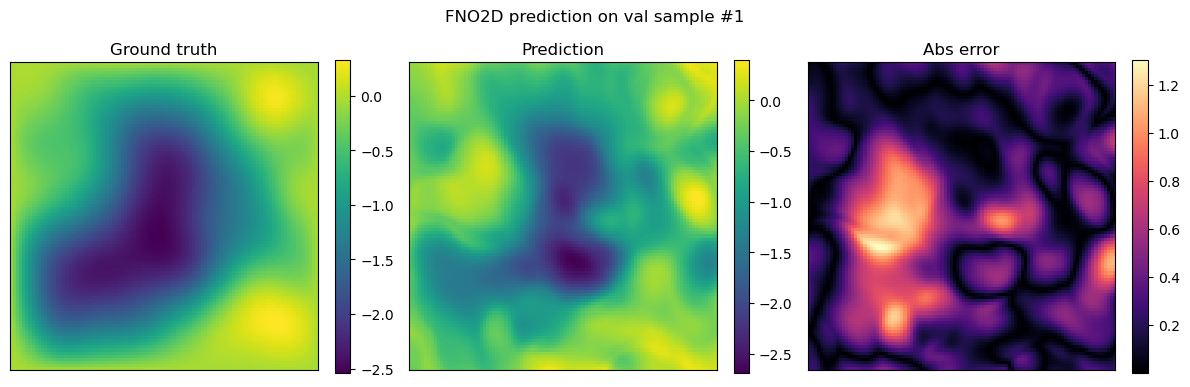

In [107]:
# --- pick one sample from val_ds ---
idx = 1  # choose which sample to visualize
x_in, y_true = val_ds[idx]      # shapes: (C_in,N,N), (1,N,N)
N = y_true.shape[-1]

x_in_t = x_in.unsqueeze(0).to(device, dtype=torch.float32)   # (1,C_in,N,N)
with torch.no_grad():
    y_pred_t = model(x_in_t)   # (1,1,N,N)

y_pred = y_pred_t.cpu().numpy()[0,0]   # (N,N)
y_true = y_true.numpy()[0]             # (N,N)

# --- plot ---
fig, axs = plt.subplots(1,3, figsize=(12,4))
im0 = axs[0].imshow(y_true, origin="lower", cmap="viridis")
axs[0].set_title("Ground truth")
plt.colorbar(im0, ax=axs[0], fraction=0.046)

im1 = axs[1].imshow(y_pred, origin="lower", cmap="viridis")
axs[1].set_title("Prediction")
plt.colorbar(im1, ax=axs[1], fraction=0.046)

im2 = axs[2].imshow(np.abs(y_pred - y_true), origin="lower", cmap="magma")
axs[2].set_title("Abs error")
plt.colorbar(im2, ax=axs[2], fraction=0.046)

for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle(f"FNO2D prediction on val sample #{idx}")
plt.tight_layout()

## Hyperparameter sweep

In [ ]:
import itertools
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from copy import deepcopy
import json, time, os



DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

def make_loader(ds, batch_size, shuffle=False):
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

def train_one_epoch(model, optimizer, loss_fn, loader):
    model.train()
    total, count = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        pred = model(xb)
        loss = loss_fn(pred, yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * xb.size(0)
        count += xb.size(0)
    return total / count

@torch.no_grad()
def evaluate(model, loss_fn, loader):
    model.eval()
    total, count = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        pred = model(xb)
        loss = loss_fn(pred, yb)
        total += loss.item() * xb.size(0)
        count += xb.size(0)
    return total / count

def train_trial(cfg, train_ds, val_ds, epochs=50):
    train_loader = make_loader(train_ds, batch_size=cfg["batch_size"], shuffle=True)
    val_loader   = make_loader(val_ds, batch_size=cfg["batch_size"], shuffle=False)

    model = FNO2d(
        in_channels=cfg["in_channels"],
        out_channels=cfg["out_channels"],
        width=cfg["width"],
        modes=cfg["modes"],
        n_layers=cfg["n_layers"],
        pad=cfg.get("pad",0),
    ).to(DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    loss_fn   = nn.MSELoss()

    best_val, best_state = float("inf"), None
    history = {"train": [], "val": []}

    for ep in range(epochs):
        tr = train_one_epoch(model, optimizer, loss_fn, train_loader)
        val = evaluate(model, loss_fn, val_loader)
        history["train"].append(tr)
        history["val"].append(val)

        if val < best_val:
            best_val = val
            best_state = deepcopy(model.state_dict())

        print(f"[{ep+1:03d}/{epochs}] train={tr:.4e} val={val:.4e} (best {best_val:.4e})")

    model.load_state_dict(best_state)
    return best_val, history

def sweep(train_ds, val_ds, outdir="sweep_results", epochs=50):
    os.makedirs(outdir, exist_ok=True)

    
    

    keys = list(search_space.keys())
    combos = list(itertools.product(*search_space.values()))
    print(f"Total trials: {len(combos)}")

    results = []
    for i, values in enumerate(combos, 1):
        cfg = dict(zip(keys, values))
        print(f"\n=== Trial {i}/{len(combos)} :: {cfg} ===")
        try:
            best_val, history = train_trial(cfg, train_ds, val_ds, epochs=epochs)
            results.append({"cfg": cfg, "best_val": best_val})
            with open(os.path.join(outdir, f"trial_{i}.json"), "w") as f:
                json.dump({"cfg": cfg, "history": history, "best_val": best_val}, f, indent=2)
        except Exception as e:
            print(f"Trial failed: {e}")

    # sort by best validation
    results.sort(key=lambda r: r["best_val"])
    print("\n===== Leaderboard =====")
    for r in results[:5]:
        print(f"val={r['best_val']:.4e} | {r['cfg']}")
    return results

# Usage:
# best_runs = sweep(train_ds, val_ds, epochs=50)


In [21]:
best_runs = sweep(train_ds, val_ds, epochs=100)

Total trials: 216

=== Trial 1/216 :: {'width': 32, 'modes': (12, 12), 'n_layers': 3, 'lr': 0.001, 'wd': 0.0001, 'batch_size': 8, 'in_channels': 3, 'out_channels': 1} ===
[001/100] train=6.7152e-01 val=6.0732e-01 (best 6.0732e-01)
[002/100] train=5.6681e-01 val=5.2408e-01 (best 5.2408e-01)
[003/100] train=4.7510e-01 val=4.7837e-01 (best 4.7837e-01)
[004/100] train=4.7972e-01 val=4.7784e-01 (best 4.7784e-01)
[005/100] train=4.4924e-01 val=4.6002e-01 (best 4.6002e-01)
[006/100] train=4.4242e-01 val=4.5039e-01 (best 4.5039e-01)
[007/100] train=4.3454e-01 val=4.4629e-01 (best 4.4629e-01)
[008/100] train=4.3873e-01 val=4.5488e-01 (best 4.4629e-01)
[009/100] train=4.3906e-01 val=4.5281e-01 (best 4.4629e-01)
[010/100] train=4.4362e-01 val=4.5515e-01 (best 4.4629e-01)
[011/100] train=4.3359e-01 val=4.5736e-01 (best 4.4629e-01)
[012/100] train=4.4989e-01 val=4.7178e-01 (best 4.4629e-01)
[013/100] train=4.5830e-01 val=4.7470e-01 (best 4.4629e-01)
[014/100] train=4.5416e-01 val=4.7214e-01 (best 4

KeyboardInterrupt: 